Q1

In [1]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """
Technology makes our lives easier and more connected.
Artificial intelligence helps computers learn from data.
Students use technology to improve their knowledge and skills.
Online learning provides access to education from anywhere.
Robots help people perform difficult and repetitive tasks.
I believe technology will create many opportunities in the future.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():\n", clean_text.split())
print("\nUsing word_tokenize():\n", word_tokenize(clean_text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nWords after Stopword Removal:\n", filtered_words)

# 5. Word frequency distribution
frequency = FreqDist(filtered_words)
print("\nWord Frequency Distribution:")
print(frequency.most_common())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Cleaned Text:
 
technology makes our lives easier and more connected
artificial intelligence helps computers learn from data
students use technology to improve their knowledge and skills
online learning provides access to education from anywhere
robots help people perform difficult and repetitive tasks
i believe technology will create many opportunities in the future


Word Tokens:
 ['technology', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'connected', 'artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'students', 'use', 'technology', 'to', 'improve', 'their', 'knowledge', 'and', 'skills', 'online', 'learning', 'provides', 'access', 'to', 'education', 'from', 'anywhere', 'robots', 'help', 'people', 'perform', 'difficult', 'and', 'repetitive', 'tasks', 'i', 'believe', 'technology', 'will', 'create', 'many', 'opportunities', 'in', 'the', 'future']

Sentence Tokens:
 ['\nTechnology makes our lives easier and more connected.', 'Artificial intelligence helps

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Q2


In [2]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('wordnet')
nltk.download('omw-1.4')

# 1. Extract alphabetic words only
clean_text = re.sub(r'[^\w\s]', '', text.lower())
alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', clean_text)

print("Alphabetic Words:\n", alphabetic_words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in alphabetic_words
    if word not in stop_words
]

print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)

# 5. Compare outputs
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(f"{original:15} Stem: {stem:12} Lemma: {lemma}")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['technology', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'connected', 'artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'students', 'use', 'technology', 'to', 'improve', 'their', 'knowledge', 'and', 'skills', 'online', 'learning', 'provides', 'access', 'to', 'education', 'from', 'anywhere', 'robots', 'help', 'people', 'perform', 'difficult', 'and', 'repetitive', 'tasks', 'i', 'believe', 'technology', 'will', 'create', 'many', 'opportunities', 'in', 'the', 'future']

After Stopword Removal:
 ['technology', 'makes', 'lives', 'easier', 'connected', 'artificial', 'intelligence', 'helps', 'computers', 'learn', 'data', 'students', 'use', 'technology', 'improve', 'knowledge', 'skills', 'online', 'learning', 'provides', 'access', 'education', 'anywhere', 'robots', 'help', 'people', 'perform', 'difficult', 'repetitive', 'tasks', 'believe', 'technology', 'create', 'many', 'opportunities', 'future']

Stemmed Words:
 ['technolog', 'make', 'live

Q3

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

documents = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning uses data to train intelligent computer systems.",
    "Blockchain technology provides secure and transparent digital transactions."
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(documents)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

# 3. Top 3 keywords from each text
print("\nTop 3 TF-IDF Keywords:")
for i, document in enumerate(documents):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[::-1][:3]

    keywords = [
        (feature_names[index], round(scores[index], 3))
        for index in top_indices
    ]

    print(f"\nText {i + 1}: {document}")
    print("Top Keywords:", keywords)

Bag of Words Vocabulary:
['and' 'artificial' 'blockchain' 'computer' 'computers' 'data' 'digital'
 'helps' 'intelligence' 'intelligent' 'learn' 'learning' 'machine'
 'problems' 'provides' 'secure' 'solve' 'systems' 'technology' 'to'
 'train' 'transactions' 'transparent' 'uses']

Bag of Words Matrix:
[[1 1 0 0 1 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 1]
 [1 0 1 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 1 0]]

TF-IDF Matrix:
[[0.276 0.363 0.    0.    0.363 0.    0.    0.363 0.363 0.    0.363 0.
  0.    0.363 0.    0.    0.363 0.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.333 0.    0.333 0.    0.    0.    0.333 0.    0.333
  0.333 0.    0.    0.    0.    0.333 0.    0.333 0.333 0.    0.    0.333]
 [0.276 0.    0.363 0.    0.    0.    0.363 0.    0.    0.    0.    0.
  0.    0.    0.363 0.363 0.    0.    0.363 0.    0.    0.363 0.363 0.   ]]

Top 3 TF-IDF Keywords:

Text 1: Artificial intelligence helps computers learn and solv

Q4

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ai_text = """
Artificial intelligence enables machines to learn from data.
AI systems solve problems and support decision making.
Machine learning improves predictions using historical information.
AI is used in healthcare, education, and automation.
"""

blockchain_text = """
Blockchain stores information in a distributed digital ledger.
It provides secure and transparent digital transactions.
Cryptography protects records from unauthorized modification.
Blockchain is used in finance and digital asset management.
"""

# 1. Preprocess and tokenize
def preprocess(text):
    text = text.lower()
    return re.findall(r'\b[a-z]+\b', text)

tokens_ai = preprocess(ai_text)
tokens_blockchain = preprocess(blockchain_text)

print("AI Tokens:\n", tokens_ai)
print("\nBlockchain Tokens:\n", tokens_blockchain)

# 2(a). Jaccard Similarity
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

# 2(b). Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([ai_text, blockchain_text])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

# 3. Compare results
print("\nComparison:")
print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))

AI Tokens:
 ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'solve', 'problems', 'and', 'support', 'decision', 'making', 'machine', 'learning', 'improves', 'predictions', 'using', 'historical', 'information', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'automation']

Blockchain Tokens:
 ['blockchain', 'stores', 'information', 'in', 'a', 'distributed', 'digital', 'ledger', 'it', 'provides', 'secure', 'and', 'transparent', 'digital', 'transactions', 'cryptography', 'protects', 'records', 'from', 'unauthorized', 'modification', 'blockchain', 'is', 'used', 'in', 'finance', 'and', 'digital', 'asset', 'management']

Common Words: {'is', 'information', 'and', 'in', 'from', 'used'}
Jaccard Similarity: 0.125
Cosine Similarity: 0.1546

Comparison:
Jaccard Similarity: 0.125
Cosine Similarity: 0.1546


Q5

Sentiment Analysis Results:

Review 1: This phone has an amazing camera and excellent battery life.
Polarity: 0.800
Subjectivity: 0.950
Sentiment: Positive

Review 2: I love this product because it is fast and easy to use.
Polarity: 0.378
Subjectivity: 0.678
Sentiment: Positive

Review 3: The quality is terrible and the battery drains quickly.
Polarity: -0.333
Subjectivity: 0.750
Sentiment: Negative

Review 4: The product is disappointing and the customer service is poor.
Polarity: -0.500
Subjectivity: 0.650
Sentiment: Negative

Review 5: The phone is okay and works as expected.
Polarity: 0.200
Subjectivity: 0.450
Sentiment: Positive



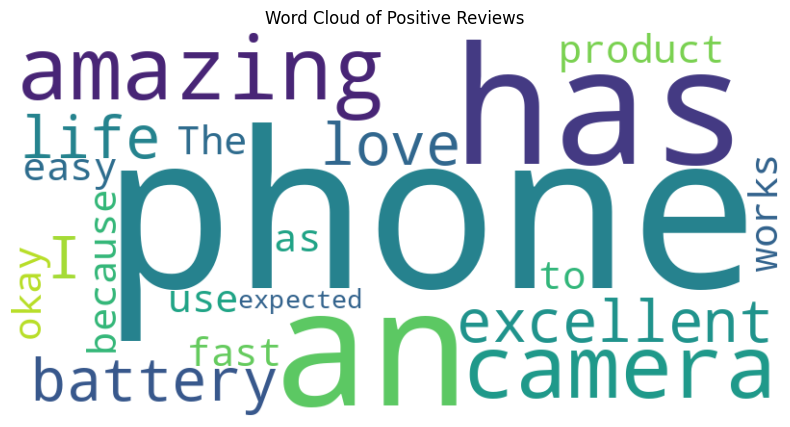

In [5]:
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This phone has an amazing camera and excellent battery life.",
    "I love this product because it is fast and easy to use.",
    "The quality is terrible and the battery drains quickly.",
    "The product is disappointing and the customer service is poor.",
    "The phone is okay and works as expected."
]

positive_reviews = []

print("Sentiment Analysis Results:\n")

# 1. Find polarity and subjectivity
for i, review in enumerate(reviews, start=1):
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    # 2. Classify sentiment
    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review {i}: {review}")
    print(f"Polarity: {polarity:.3f}")
    print(f"Subjectivity: {subjectivity:.3f}")
    print(f"Sentiment: {sentiment}\n")

# 3. Create word cloud for positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        stopwords=set(['this', 'and', 'it', 'is'])
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

Q6

In [6]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
training_text = """
Technology is changing the world every day.
Artificial intelligence helps computers learn from data.
Machine learning allows systems to identify patterns and make predictions.
Students use technology to improve their knowledge and skills.
Online education provides learning opportunities to people everywhere.
Robots help humans perform difficult and repetitive tasks.
Modern computers process information quickly and accurately.
Technology connects people and makes communication easier.
Scientists develop new tools to solve real world problems.
Artificial intelligence is useful in healthcare, education, and business.
Machine learning improves when models learn from more examples.
Students can use computers to practice programming and solve problems.
Technology creates opportunities for innovation and future growth.
The future will bring smarter machines and better digital services.
People must use technology responsibly to benefit society.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1
print("Total Unique Words:", total_words)

# 3. Create input sequences
input_sequences = []

for line in training_text.lower().split("."):
    line = line.strip()

    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequence = token_list[:i + 1]
        input_sequences.append(sequence)

# Pad all sequences to equal length
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

# Separate input words (X) and target word (y)
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

# 4. Build the LSTM model
model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

# Build model before displaying summary
model.build(input_shape=(None, X.shape[1]))

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

# 5. Train the model
model.fit(X, y, epochs=150, verbose=0)

print("\nModel training completed!")

# 6. Generate text using a seed word
def generate_text(seed_text, next_words=8):
    result = seed_text.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]

        # Handle a seed word not present in the vocabulary
        if not token_list:
            break

        token_list = pad_sequences(
            [token_list],
            maxlen=X.shape[1],
            padding="pre",
            truncating="pre"
        )

        predictions = model.predict(token_list, verbose=0)[0]

        # Sample a word using predicted probabilities
        valid_indices = np.where(predictions > 0)[0]
        probabilities = predictions[valid_indices]
        probabilities = probabilities / probabilities.sum()

        predicted_index = np.random.choice(
            valid_indices,
            p=probabilities
        )

        output_word = tokenizer.index_word.get(predicted_index)

        if output_word is None:
            break

        result += " " + output_word

    return result

# 7. Generate three lines
seed_word = "technology"

print("\nGenerated Text:")
for i in range(3):
    print(f"Line {i + 1}: {generate_text(seed_word, 8)}")


Total Unique Words: 88
Input Shape: (111, 9)
Target Shape: (111,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 9, 32)          │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 88)             │         5,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,368 (130.34 KB)

 Trainable params: 33,368 (130.34 KB)

 Non-trainable params: 0 (0.00 B)


Model training completed!

Generated Text:
Line 1: technology must technology makes makes and easier better technology
Line 2: technology people people future and communication communication easier their
Line 3: technology humans computers and makes and easier develop online
